# Red neuronal multicapa 2-2-1 con notas reales

## Procedencia y correspondencia con el examen
Se usa **UCI Student Performance** (Matemática), CC BY 4.0. G1 y G2 reemplazan entradas sintéticas y G3 deriva la clase; se conservan arquitectura, sigmoide, tasa y una actualización.

In [1]:
from pathlib import Path
import json, sys, tempfile
import pandas as pd
from IPython.display import display, Image
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from mlp import StudentDataset, GradeNormalizer, DenseLayer, Sigmoid, BinaryCrossEntropy, MLP221, TrainingTrace, run_exercise

## Teoría y fases
Tras una partición estratificada sin fuga, se normaliza una muestra. El forward usa capas densas y sigmoide; BCE mide el error; backprop obtiene deltas y gradientes; la tasa ajusta pesos y sesgos antes de verificar otro forward.

,fase,operación
0,Preparación y partición,Derivar la clase sin usar G3 como entrada y es...
1,Normalización de la muestra,"Aplicar x1=G1/20, x2=G2/20 y y=1 si G3>=10."
2,Inicialización 2-2-1,Cargar pesos y sesgos deterministas para dos e...
3,Propagación hacia adelante,"Calcular z_h=W_hx+b_h, h=σ(z_h), z_o=W_oh+b_o ..."
4,Pérdida,Calcular entropía cruzada binaria −[y ln ŷ +(1...
5,Retropropagación,Propagar δ_o=ŷ−y y δ_h=(W_o δ_o)⊙h(1−h); forma...
6,Actualización de parámetros,Aplicar θ_nuevo=θ−η∇θ a pesos y sesgos.
7,Verificación posterior,Repetir la propagación y comprobar el cambio d...


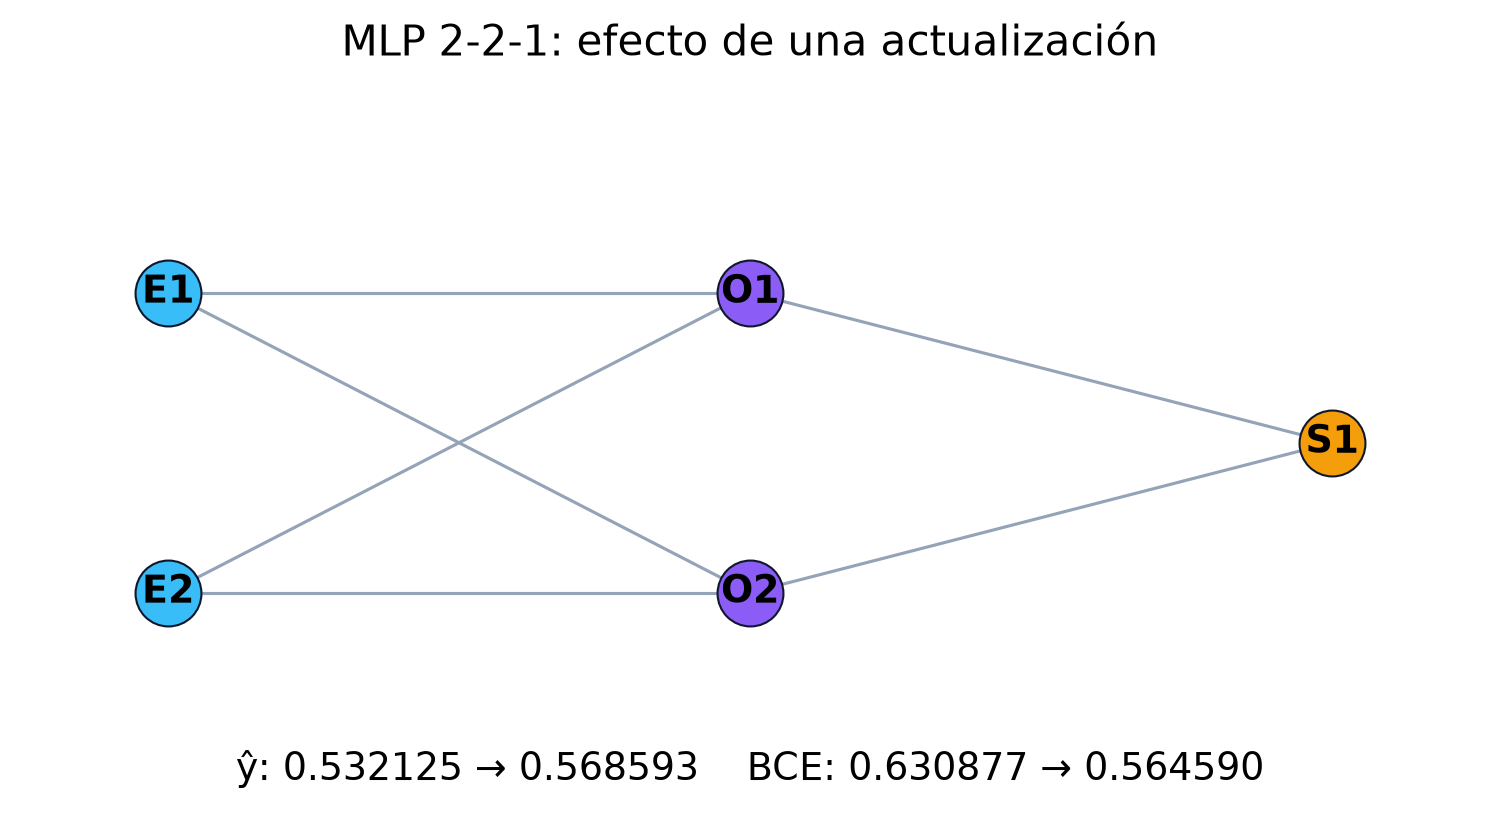

In [2]:
temporary = tempfile.TemporaryDirectory()
manifest = run_exercise(ROOT / "data/raw/student-mat.csv", ROOT / "data/metadata/mlp.json", ROOT / "configs/mlp.json", Path(temporary.name))
display(pd.DataFrame([{"fase": stage["title_es"], "operación": stage["operation"]} for stage in manifest["stages"]]))
display(Image(filename=str(Path(temporary.name) / "network_update.png")))

## Responsabilidades OOP
`StudentDataset` divide datos; `GradeNormalizer` escala; `DenseLayer`, `Sigmoid` y `BinaryCrossEntropy` hacen operaciones explícitas; `MLP221` coordina aprendizaje; `TrainingTrace` conserva gradientes y parámetros.

In [3]:
display(pd.DataFrame(manifest["stages"][7]["outputs"].items(), columns=["medida", "valor"]))
display(pd.DataFrame(manifest["pdf_mapping"]))
print(manifest["summary"]["conclusion_es"])

,medida,valor
0,prediction_before,0.532125
1,prediction_after,0.568593
2,loss_before,0.630877
3,loss_after,0.564590


,pdf_element,original_value,treatment,replacement,justification
0,entrada_asistencia,0.8,replaced,G1/20 = 0.75,Se usa la primera nota real normalizada.
1,entrada_actividades,0.6,replaced,G2/20 = 0.70,Se usa la segunda nota real normalizada.
2,clase_esperada,aprobado,replaced,G3=15 implica y=1,La etiqueta se deriva del resultado real sin u...
3,arquitectura_y_activacion,2-2-1 con sigmoide,retained,2-2-1 con sigmoide,Conserva la estructura solicitada.
4,tasa_aprendizaje,0.2,retained,0.2,Se conserva para la actualización manual.
5,inicializacion,pesos no completamente especificados,replaced,pesos y sesgos deterministas declarados,Permite reproducir propagación y retropropagac...


Una actualización eleva ŷ de 0.532125 a 0.568593 y reduce BCE de 0.630877 a 0.564590.


## Conclusión y limitaciones
Una actualización acerca la salida a la clase correcta y reduce BCE. No es una evaluación de un clasificador completo; las notas están correlacionadas y la población no representa a UNMSM.

In [4]:
canonical = json.loads((ROOT / "results/mlp/result.json").read_text(encoding="utf-8"))
assert manifest == canonical
print("Paridad verificada: notebook = manifiesto MLP canónico")

Paridad verificada: notebook = manifiesto MLP canónico
